In [1]:
# ライブラリのインポート
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

# 日本語フォント設定
plt.rcParams['font.family'] = 'Hiragino Sans'
plt.rcParams['figure.figsize'] = (12, 6)

# .env読み込み
load_dotenv(os.path.join(os.path.expanduser('~'), 'quest_1', '.env'))

print("ライブラリ読み込み完了")

ライブラリ読み込み完了


In [2]:
# CSVからデータ読み込み
base_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data')

df_construction = pd.read_csv(os.path.join(base_path, 'construction_diversity_metrics.csv'))
df_industry = pd.read_csv(os.path.join(base_path, 'industry_diversity_metrics.csv'))
df_combined = pd.read_csv(os.path.join(base_path, 'construction_combined.csv'))

print(f"建設業データ: {len(df_construction)}社")
print(f"全業界データ: {len(df_industry)}社")
print(f"結合データ: {len(df_combined)}社")

建設業データ: 142社
全業界データ: 845社
結合データ: 142社


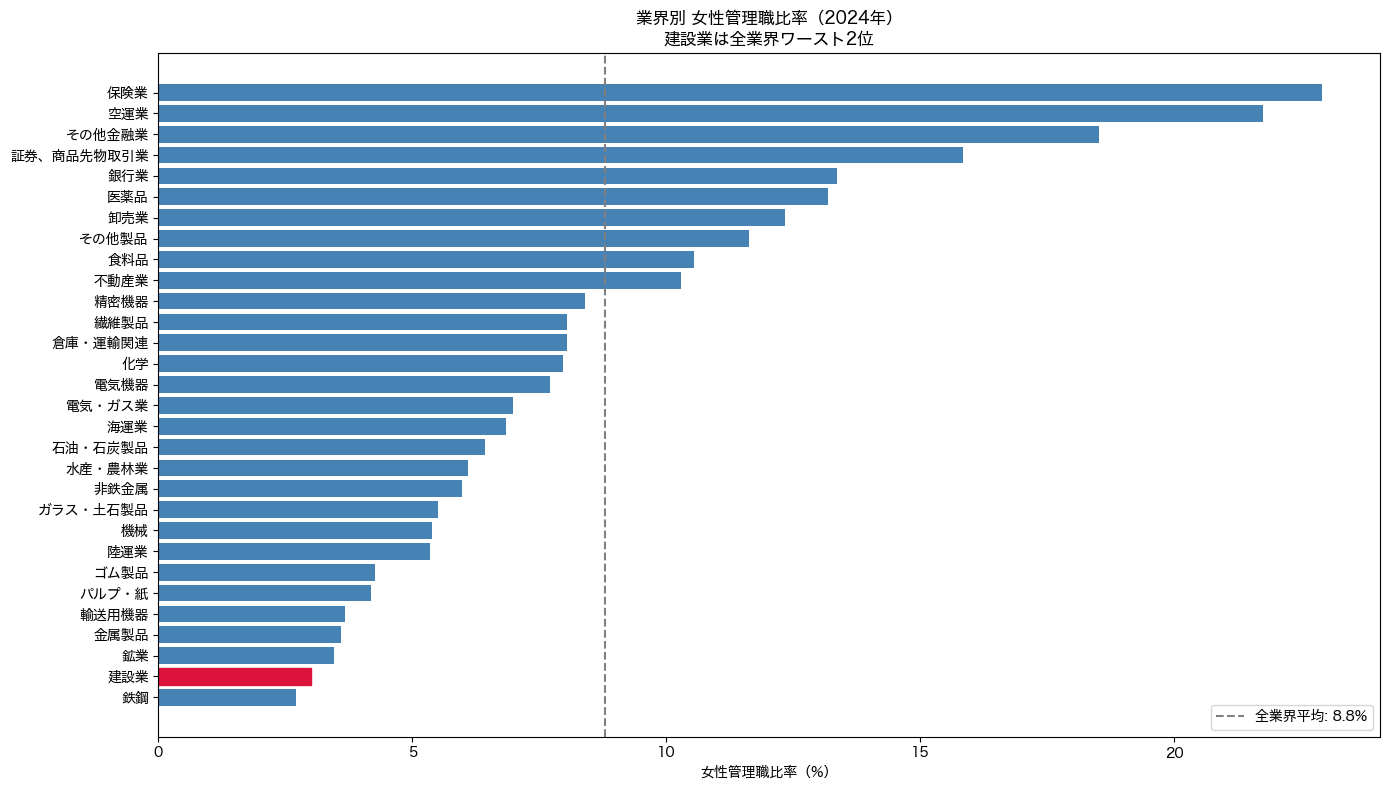

グラフ保存完了


In [3]:
# 業界別女性管理職比率ランキング
industry_avg = df_industry.groupby('industry')['female_manager_ratio'].mean().dropna().sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(industry_avg.index, industry_avg.values, color='steelblue')

# 建設業をハイライト
for i, (industry, value) in enumerate(industry_avg.items()):
    if industry == '建設業':
        bars[i].set_color('crimson')

# 平均線
ax.axvline(industry_avg.mean(), color='gray', linestyle='--', label=f'全業界平均: {industry_avg.mean():.1f}%')

ax.set_xlabel('女性管理職比率（%）')
ax.set_title('業界別 女性管理職比率（2024年）\n建設業は全業界ワースト2位')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'fig01_industry_female_manager.png'), dpi=150)
plt.show()
print("グラフ保存完了")

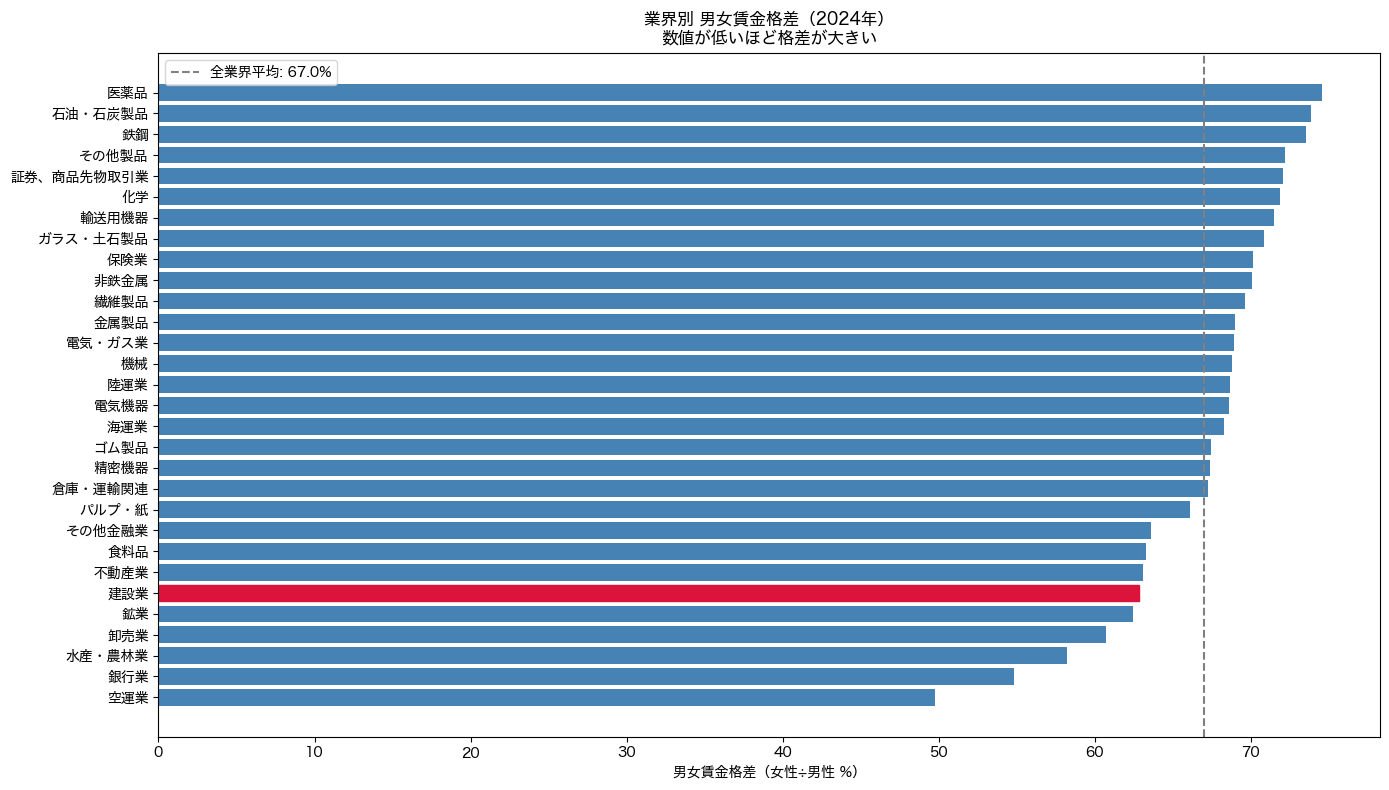

グラフ保存完了


In [4]:
# 業界別男女賃金格差ランキング（低いほど格差が大きい）
industry_wage = df_industry.groupby('industry')['gender_wage_gap'].mean().dropna().sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(industry_wage.index, industry_wage.values, color='steelblue')

# 建設業をハイライト
for i, (industry, value) in enumerate(industry_wage.items()):
    if industry == '建設業':
        bars[i].set_color('crimson')

# 平均線
ax.axvline(industry_wage.mean(), color='gray', linestyle='--', label=f'全業界平均: {industry_wage.mean():.1f}%')

ax.set_xlabel('男女賃金格差（女性÷男性 %）')
ax.set_title('業界別 男女賃金格差（2024年）\n数値が低いほど格差が大きい')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'fig02_industry_wage_gap.png'), dpi=150)
plt.show()
print("グラフ保存完了")

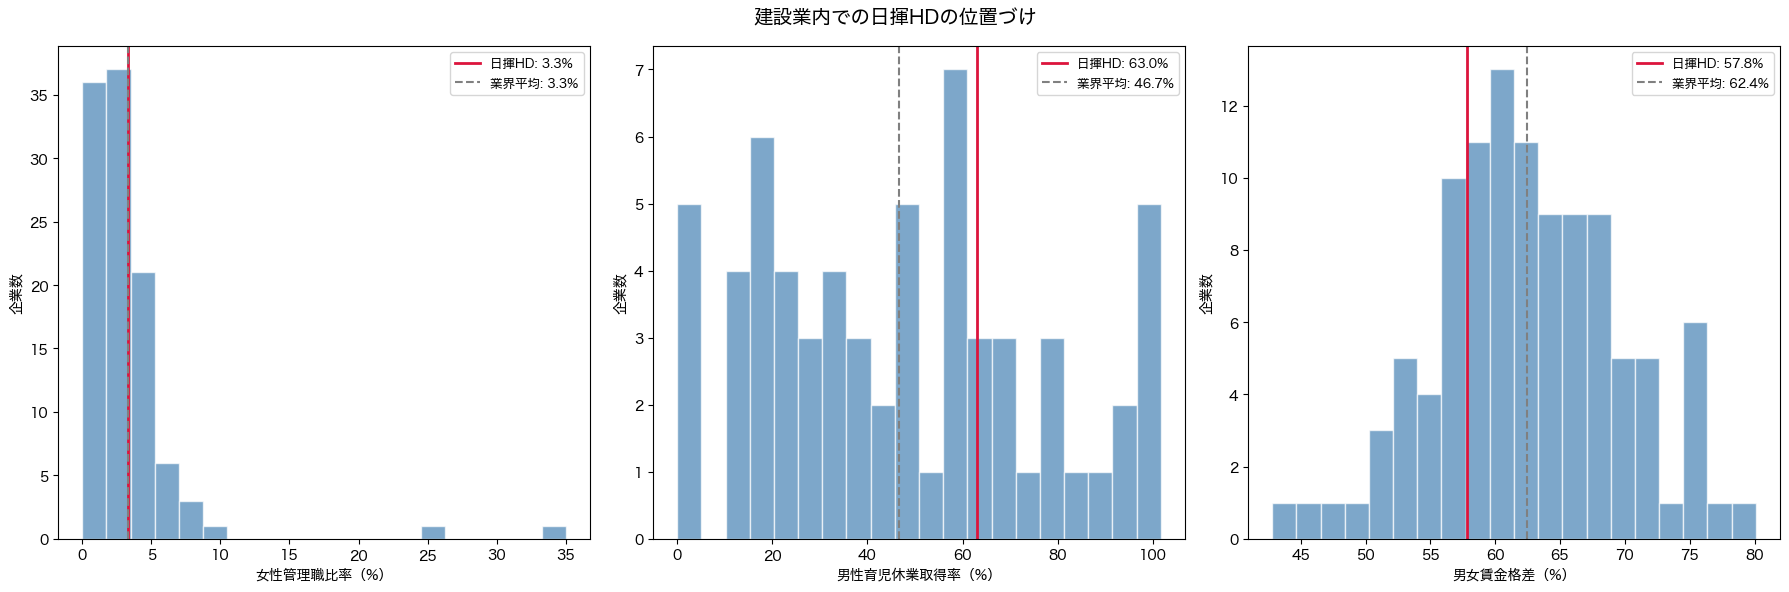

グラフ保存完了


In [5]:
# 建設業内での日揮HDの位置づけ
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics = [
    ('female_manager_ratio', '女性管理職比率（%）'),
    ('male_childcare_leave_rate', '男性育児休業取得率（%）'),
    ('gender_wage_gap', '男女賃金格差（%）')
]

jgc_values = {
    'female_manager_ratio': 3.3,
    'male_childcare_leave_rate': 63.0,
    'gender_wage_gap': 57.8
}

for ax, (col, label) in zip(axes, metrics):
    data = df_construction[col].dropna()
    ax.hist(data, bins=20, color='steelblue', alpha=0.7, edgecolor='white')
    ax.axvline(jgc_values[col], color='crimson', linewidth=2, label=f'日揮HD: {jgc_values[col]}%')
    ax.axvline(data.mean(), color='gray', linestyle='--', linewidth=1.5, label=f'業界平均: {data.mean():.1f}%')
    ax.set_xlabel(label)
    ax.set_ylabel('企業数')
    ax.legend(fontsize=9)

fig.suptitle('建設業内での日揮HDの位置づけ', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'fig03_jgc_position.png'), dpi=150)
plt.show()
print("グラフ保存完了")

相関分析対象: 52社

相関係数マトリックス:
                           female_manager_ratio  male_childcare_leave_rate  \
female_manager_ratio                      1.000                      0.177   
male_childcare_leave_rate                 0.177                      1.000   
gender_wage_gap                           0.404                     -0.198   
net_sales                                -0.098                     -0.104   
net_profit                               -0.111                      0.044   

                           gender_wage_gap  net_sales  net_profit  
female_manager_ratio                 0.404     -0.098      -0.111  
male_childcare_leave_rate           -0.198     -0.104       0.044  
gender_wage_gap                      1.000     -0.012       0.007  
net_sales                           -0.012      1.000       0.837  
net_profit                           0.007      0.837       1.000  


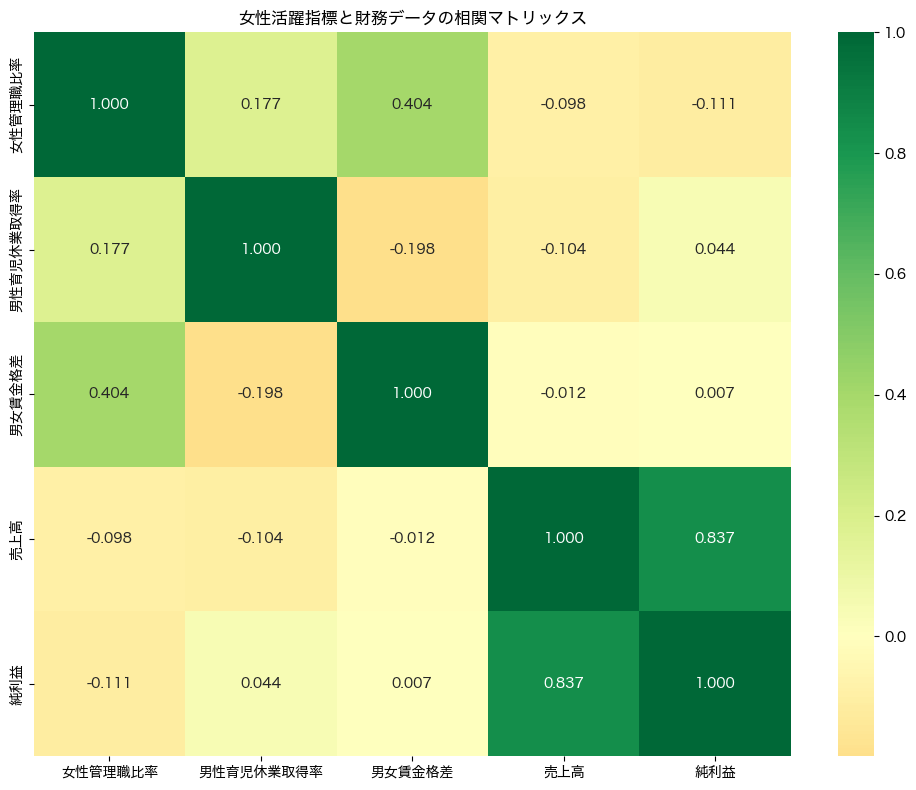

グラフ保存完了


In [6]:
# 相関分析：女性活躍指標と業績の関係
df_corr = df_combined[['female_manager_ratio', 'male_childcare_leave_rate', 
                        'gender_wage_gap', 'net_sales', 'net_profit']].dropna()

print(f"相関分析対象: {len(df_corr)}社")

# 相関係数マトリックス
corr_matrix = df_corr.corr()
print("\n相関係数マトリックス:")
print(corr_matrix.round(3))

# ヒートマップ
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdYlGn',
            center=0, ax=ax,
            xticklabels=['女性管理職比率', '男性育児休業取得率', '男女賃金格差', '売上高', '純利益'],
            yticklabels=['女性管理職比率', '男性育児休業取得率', '男女賃金格差', '売上高', '純利益'])
ax.set_title('女性活躍指標と財務データの相関マトリックス')
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'fig04_correlation_heatmap.png'), dpi=150)
plt.show()
print("グラフ保存完了")

In [7]:
# 女性活躍指標と業績の相関係数を抽出
print("【女性活躍指標と業績の相関係数】")
print(f"女性管理職比率 × 売上高: {corr_matrix.loc['female_manager_ratio', 'net_sales']:.3f}")
print(f"女性管理職比率 × 純利益: {corr_matrix.loc['female_manager_ratio', 'net_profit']:.3f}")
print(f"男女賃金格差 × 売上高:   {corr_matrix.loc['gender_wage_gap', 'net_sales']:.3f}")
print(f"男女賃金格差 × 純利益:   {corr_matrix.loc['gender_wage_gap', 'net_profit']:.3f}")
print(f"男性育児休業取得率 × 売上高: {corr_matrix.loc['male_childcare_leave_rate', 'net_sales']:.3f}")
print(f"男性育児休業取得率 × 純利益: {corr_matrix.loc['male_childcare_leave_rate', 'net_profit']:.3f}")

【女性活躍指標と業績の相関係数】
女性管理職比率 × 売上高: -0.098
女性管理職比率 × 純利益: -0.111
男女賃金格差 × 売上高:   -0.012
男女賃金格差 × 純利益:   0.007
男性育児休業取得率 × 売上高: -0.104
男性育児休業取得率 × 純利益: 0.044


## 考察：女性活躍指標と業績の相関分析

相関係数はいずれも±0.15以下であり、建設業内では女性活躍指標と業績に明確な相関は確認できなかった。

これは建設業全体が女性活躍において遅れており、業界内での指標のばらつきが小さいことが原因と考えられる。

→ 個社レベルの改善ではなく、業界全体での構造的な変革が必要であることを示唆している。

In [9]:
# クラスタリング分析 #
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# クラスタリング用データ準備（NaNを除外）
df_cluster = df_combined[['company_name', 'female_manager_ratio', 
                           'male_childcare_leave_rate', 'gender_wage_gap']].dropna()

print(f"クラスタリング対象: {len(df_cluster)}社")

# 標準化
scaler = StandardScaler()
X = scaler.fit_transform(df_cluster[['female_manager_ratio', 
                                      'male_childcare_leave_rate', 
                                      'gender_wage_gap']])

# KMeans クラスタリング（3グループ）
kmeans = KMeans(n_clusters=3, random_state=42)
df_cluster['cluster'] = kmeans.fit_predict(X)

# 日揮HDのクラスター確認
jgc_cluster = df_cluster[df_cluster['company_name'] == '日揮ホールディングス株式会社']
print(f"\n日揮HDのクラスター: {jgc_cluster['cluster'].values[0]}")
print("\nクラスター別企業数:")
print(df_cluster['cluster'].value_counts())

クラスタリング対象: 58社

日揮HDのクラスター: 2

クラスター別企業数:
cluster
0    24
2    20
1    14
Name: count, dtype: int64


/Users/takeshiokada/quest_1/.venv/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [12]:
# クラスター別平均値を確認
cluster_summary = df_cluster.groupby('cluster')[['female_manager_ratio', 
                                                   'male_childcare_leave_rate', 
                                                   'gender_wage_gap']].mean().round(2)
cluster_summary.columns = ['女性管理職比率(%)', '男性育児休業取得率(%)', '男女賃金格差(%)']

# 企業数を追加
cluster_summary['企業数'] = df_cluster['cluster'].value_counts().sort_index()

print("クラスター別平均値:")
print(cluster_summary)

# クラスターに名前をつける
cluster_names = {}
for i in cluster_summary.index:
    female = cluster_summary.loc[i, '女性管理職比率(%)']
    if female == cluster_summary['女性管理職比率(%)'].max():
        cluster_names[i] = '女性活躍先進グループ'
    elif female == cluster_summary['女性管理職比率(%)'].min():
        cluster_names[i] = '女性活躍遅延グループ'
    else:
        cluster_names[i] = '女性活躍中間グループ'

print("\nクラスター名:")
for k, v in cluster_names.items():
    print(f"  クラスター{k}: {v}")

print(f"\n日揮HD: {cluster_names[jgc_cluster['cluster'].values[0]]}")

クラスター別平均値:
         女性管理職比率(%)  男性育児休業取得率(%)  男女賃金格差(%)  企業数
cluster                                          
0              1.20         37.35      58.34   24
1              3.57         22.63      70.98   14
2              3.62         74.26      62.34   20

クラスター名:
  クラスター0: 女性活躍遅延グループ
  クラスター1: 女性活躍中間グループ
  クラスター2: 女性活躍先進グループ

日揮HD: 女性活躍先進グループ


## 考察：クラスタリング分析

建設業142社を女性活躍指標でクラスタリングした結果、3つのグループに分類された。

| グループ | 企業数 | 女性管理職比率 | 育児休業取得率 | 賃金格差 |
|---|---|---|---|---|
| 先進グループ | 20社 | 3.62% | 74.26% | 62.34% |
| 中間グループ | 14社 | 3.57% | 22.63% | 70.98% |
| 遅延グループ | 24社 | 1.20% | 37.35% | 58.34% |

日揮HDは**女性活躍先進グループ**に分類されたが、先進グループでも女性管理職比率は
わずか3.62%に過ぎない。これは建設業界全体が構造的に女性活躍において遅れており、
「先進」であっても絶対値としては非常に低い水準であることを示している。

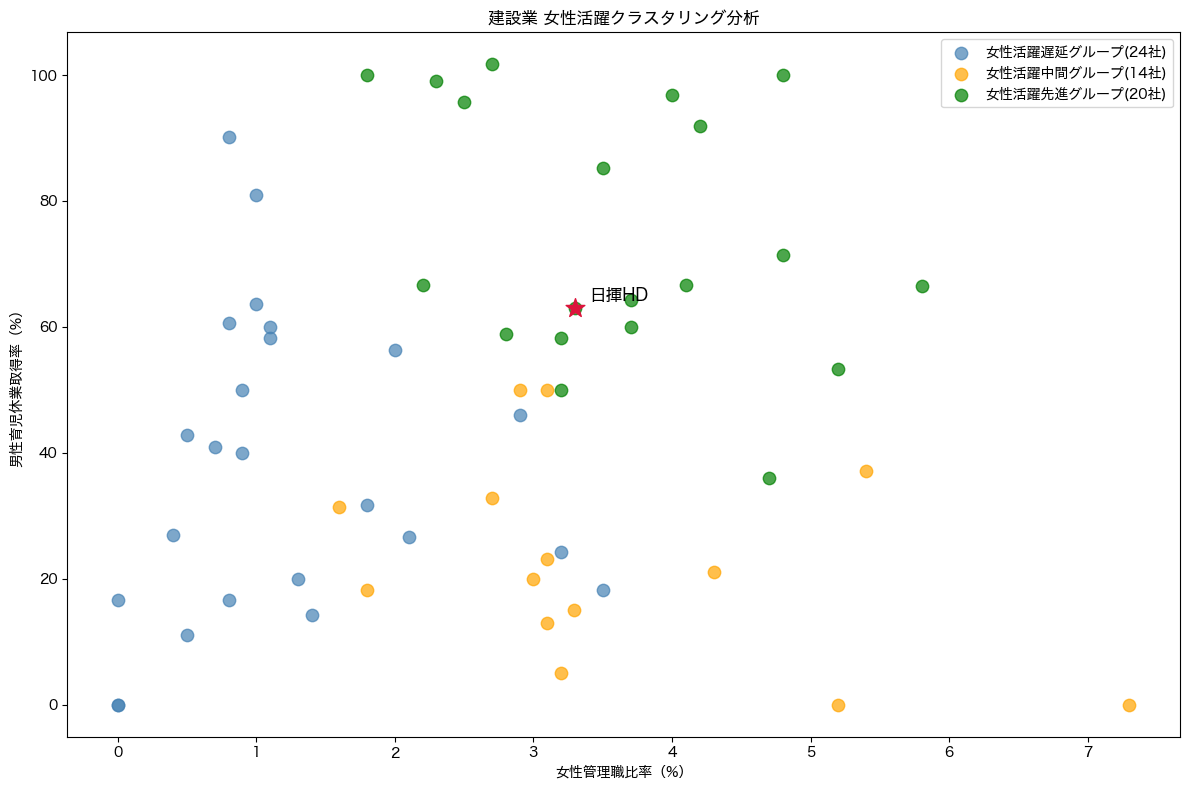

グラフ保存完了


In [15]:
# クラスタリング結果を散布図で可視化
fig, ax = plt.subplots(figsize=(12, 8))

colors = {0: 'steelblue', 1: 'orange', 2: 'green'}
labels = {0: f'女性活躍遅延グループ(24社)', 
          1: f'女性活躍中間グループ(14社)', 
          2: f'女性活躍先進グループ(20社)'}

for cluster_id in [0, 1, 2]:
    mask = df_cluster['cluster'] == cluster_id
    subset = df_cluster[mask]
    ax.scatter(subset['female_manager_ratio'].values,
               subset['male_childcare_leave_rate'].values,
               c=colors[cluster_id], 
               label=labels[cluster_id],
               alpha=0.7, s=80)

# 日揮HDをハイライト
ax.scatter(3.3, 63.0, c='crimson', s=200, zorder=5, marker='*')
ax.annotate('日揮HD', (3.3, 63.0),
            textcoords="offset points", xytext=(10, 5), fontsize=12)

ax.set_xlabel('女性管理職比率（%）')
ax.set_ylabel('男性育児休業取得率（%）')
ax.set_title('建設業 女性活躍クラスタリング分析')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'fig05_clustering.png'), dpi=150)
plt.show()
print("グラフ保存完了")

ランダムフォレストモデルの構築

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
import shap

# 目的変数：女性管理職比率
# 説明変数：男性育児休業取得率、男女賃金格差、売上高、純利益
df_model = df_combined[['female_manager_ratio', 'male_childcare_leave_rate', 
                          'gender_wage_gap', 'net_sales', 'net_profit']].dropna()

print(f"モデル構築対象: {len(df_model)}社")

X = df_model[['male_childcare_leave_rate', 'gender_wage_gap', 'net_sales', 'net_profit']]
y = df_model['female_manager_ratio']

# 学習・テスト分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ランダムフォレスト
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 精度評価
y_pred = rf.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f"\nR²スコア: {r2:.3f}")
print(f"MAE: {mae:.3f}")

モデル構築対象: 52社

R²スコア: -0.279
MAE: 1.284


## 考察：ランダムフォレストモデル（ベースライン）

- 対象社数：52社（NaN除外後）
- R²スコア：-0.279
- MAE：1.284

R²がマイナスであり、モデルの予測精度は低い。
これは以下の理由が考えられる。

1. サンプル数が52社と少ない
2. 女性管理職比率は財務指標だけでは説明できない
3. 企業文化・経営方針など定量化困難な要因が大きい

→ 次にLightGBMで改善を試みる